# NYC Taxi Fare Prediction — End-to-End Big Data Analytics with Dask Distributed

**Dataset:** *New York City Taxi Fare Prediction* `train.csv` (manually downloaded, loaded from local Colab storage)
**Engine:** Dask Distributed (`LocalCluster`) on Google Colab
**Target variable:** `fare_amount` (regression)

---

This notebook demonstrates the full big-data analytics pipeline mandated by the
COM7036M brief:

| Section | Content |
|---|---|
| **0** | Big-data processing — partitioning, repartitioning, parallel computation (Dask) |
| **1** | Data understanding & preprocessing (structure, cleaning, transformation, reduction) |
| **2** | Data wrangling (type fixes, feature engineering: haversine distance, time features, fare-per-km) |
| **3** | Descriptive analytics (summary statistics + visualisations) |
| **4** | Diagnostic analytics (correlation, hypothesis testing, regression) |
| **5** | Predictive analytics (Linear, Decision Tree, Random Forest, HistGBT — RMSE/MAE/R²) |
| **6** | Recommendations & conclusions |
| **7** | References |

**Test-driven design:** each stage ends with `assert`-based *contracts* that fail fast
if a data-quality or shape invariant is violated, so the notebook is safe to re-run
end-to-end (`Runtime → Run all`).


In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Setup — Environment

Colab ships with Dask and pandas, but we explicitly upgrade `dask[distributed]`
to a recent stable release for API consistency, then install the supporting
analytics libraries. The `_pip` helper keeps the install quiet and idempotent.


In [31]:
# --- Setup.1  Install / upgrade Dask Distributed and supporting libraries ---
import sys, subprocess

def _pip(args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)

_pip(["--upgrade", "dask[distributed]==2024.12.1"])
_pip(["pyarrow", "seaborn", "scikit-learn", "scipy", "statsmodels"])

print("Setup.1 complete — libraries installed/upgraded.")


Setup.1 complete — libraries installed/upgraded.


## Setup — Point to the manually-downloaded CSV

You have already downloaded the *New York City Taxi Fare Prediction* `train.csv`
(~5.7 GB, ~55 million rows) and uploaded it into the Colab session.

Set `TRAIN_CSV` to its path. The cell below auto-discovers the file in the usual
Colab locations (`/content`, `/content/drive/MyDrive`) and falls back to whatever
you set manually, so it works whether you uploaded straight into session storage
or mounted Google Drive.

> **Tip:** uploading a 5.7 GB file into session storage can be slow and is wiped
> when the runtime recycles. If you re-run often, mounting Google Drive
> (`from google.colab import drive; drive.mount('/content/drive')`) and pointing
> `TRAIN_CSV` at the Drive copy is more durable.


In [32]:
# --- Setup.2  Locate the local CSV ---
import os, glob

# >>> If auto-discovery fails, just hard-code your path here: <<<
TRAIN_CSV = "/content/train.csv"

# Auto-discovery: search common Colab locations for a *.csv that looks like the file
if not os.path.exists(TRAIN_CSV):
    search_globs = [
        "/content/train.csv",
        "/content/*.csv",
        "/content/drive/MyDrive/**/train.csv",
        "/content/drive/MyDrive/**/*.csv",
    ]
    found = []
    for g in search_globs:
        found += glob.glob(g, recursive=True)
    # keep the largest match — the 5.7 GB train file dwarfs test.csv
    found = sorted(set(found), key=lambda p: os.path.getsize(p) if os.path.exists(p) else 0,
                   reverse=True)
    assert found, ("Could not find the CSV. Upload it to /content or set "
                   "TRAIN_CSV manually to its full path.")
    TRAIN_CSV = found[0]

size_gb = os.path.getsize(TRAIN_CSV) / 1e9
print(f"Using CSV: {TRAIN_CSV}  ({size_gb:.2f} GB)")
assert size_gb > 0.01, "CSV looks too small — is this the right file?"


Using CSV: /content/drive/MyDrive/new-york-city-taxi-fare-prediction/train.csv  (5.70 GB)


## Setup — Start a Dask `LocalCluster`

A `LocalCluster` is Dask's lightweight, in-process distributed scheduler. Two
workers with two threads each give **four concurrent task slots**, matching a
Colab High-RAM VM's logical cores. The per-worker memory limit is set generously
because we read the full 5.7 GB file; on a High-RAM Colab instance (~50 GB) this
leaves ample headroom.

> **Reproducibility:** because we read the *entire* file, a High-RAM runtime is
> recommended (`Runtime → Change runtime type → High-RAM`).


In [33]:
# --- Setup.3  Initialise the Dask cluster ---
from dask.distributed import Client, LocalCluster, wait
import dask

cluster = LocalCluster(
    n_workers=2,
    threads_per_worker=2,
    memory_limit="12GB",          # generous; full-file read on High-RAM Colab
    dashboard_address=":0",
)
client = Client(cluster)
n_workers = len(client.scheduler_info()["workers"])
print(f"Workers: {n_workers}  |  dask {dask.__version__}")
client


INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:34261
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:35943/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38031'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:34363'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:37507 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:37507
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:54224
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:33487 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:33487
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:54236
INFO:distributed.scheduler:Receive client connection: Client-dedc5677-6e77-11f1-8291-0242ac1c000c
INFO:distributed.core:Starting establis

Workers: 2  |  dask 2024.12.1


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:35943/status,
Dashboard: http://127.0.0.1:35943/status,Workers: 2
Total threads: 4,Total memory: 22.35 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34261,Workers: 2
Dashboard: http://127.0.0.1:35943/status,Total threads: 4
Started: Just now,Total memory: 22.35 GiB
Comm: tcp://127.0.0.1:33487,Total threads: 2
Dashboard: http://127.0.0.1:43989/status,Memory: 11.18 GiB
Nanny: tcp://127.0.0.1:38031,


## Section 0 — Data Preparation: Partitioning, Repartitioning & Parallel Computation

This is the **mandatory big-data processing step**. Before any analytics, we show
three distributed-computing primitives on the full 55-million-row file:

1. **Partitioning** — split the data into independent chunks ("partitions"), each
   processed by one worker task. The number of partitions is the *upper bound on
   parallelism*.
2. **Repartitioning** — deliberately change the partition count and justify it.
3. **Parallel computation** — benchmark the same aggregation across partition
   counts to show the speed-up (and the overhead at the high end).


### 0.1  Read the CSV into a Dask DataFrame with explicit dtypes & blocksize

`dd.read_csv` with a `blocksize` partitions a single large CSV by byte-range, so
the file never has to fit in one worker's memory. We declare dtypes up front to
avoid Dask's per-partition type-inference mismatches, and parse the pickup
timestamp eagerly.


In [34]:
# --- 0.1  Read full CSV as a partitioned Dask DataFrame ---
import dask.dataframe as dd

dtypes = {
    "fare_amount":       "float32",
    "pickup_longitude":  "float32",
    "pickup_latitude":   "float32",
    "dropoff_longitude": "float32",
    "dropoff_latitude":  "float32",
    "passenger_count":   "float32",   # has occasional nulls -> float for safety
}

df_raw = dd.read_csv(
    TRAIN_CSV,
    dtype=dtypes,
    parse_dates=["pickup_datetime"],
    blocksize="128MB",                # ~128 MB byte-range partitions
    assume_missing=True,
)

print("Columns:", list(df_raw.columns))
print("Initial partitions:", df_raw.npartitions)


Columns: ['key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
Initial partitions: 44


### 0.2  Schema contract (test-driven)

A defensive assertion: if Kaggle ever changes the column set, the notebook fails
immediately with a clear message rather than producing silently-wrong analytics
downstream.


In [35]:
# --- 0.2  Schema contract ---
expected = {
    "key", "fare_amount", "pickup_datetime",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count",
}
missing = expected - set(df_raw.columns)
assert not missing, f"Schema mismatch — missing columns: {missing}"
print("Schema contract: PASS — all 8 expected columns present.")


Schema contract: PASS — all 8 expected columns present.


### 0.3  Inspect the partitioning

We materialise the per-partition row counts. With a ~128 MB blocksize on a
5.7 GB file we expect roughly 45 partitions of ~1.2 million rows each. This
confirms the byte-range split produced near-uniform partitions (no skew).


In [36]:
# --- 0.3  Inspect partition layout ---
total_rows = int(df_raw.shape[0].compute())
print(f"Total rows: {total_rows:,}")
print(f"Partition count: {df_raw.npartitions}")

part_sizes = df_raw.map_partitions(len).compute()
print(f"Mean rows/partition: {part_sizes.mean():,.0f}")
print(f"Min / Max rows/partition: {part_sizes.min():,} / {part_sizes.max():,}")


Total rows: 55,423,856
Partition count: 44
Mean rows/partition: 1,259,633
Min / Max rows/partition: 1,259,350 / 1,259,877


### 0.4  Repartition deliberately — and justify it

Two repartitioning idioms:

* **Count-based** `repartition(npartitions=32)` — useful for fixing a known
  parallelism width (e.g. benchmarking).
* **Size-based** `repartition(partition_size="100MB")` — the production-grade
  idiom: it adapts automatically to the data's in-memory size, so the *same code*
  produces sensible partitions whether the input is 5 GB or 50 GB.

**Justification:** the raw byte-range partitions are fine for reading, but after
we drop columns and cast to `float32`, each partition shrinks. Consolidating into
fewer, larger partitions reduces per-task scheduling overhead during the many
group-by aggregations in Sections 3–4.


In [37]:
# --- 0.4  Repartition (count-based and size-based) ---
df_count = df_raw.repartition(npartitions=32)
print(f"Count-based  -> {df_count.npartitions} partitions")

df_size = df_raw.repartition(partition_size="100MB")
print(f"Size-based   -> {df_size.npartitions} partitions")

# We proceed with a fixed 32-partition layout for predictable parallelism.
df_raw = df_count
assert df_raw.npartitions == 32, "Repartition did not yield 32 partitions"
print("Repartition contract: PASS")


Count-based  -> 32 partitions
Size-based   -> 44 partitions
Repartition contract: PASS


### 0.5  Benchmark parallel computation

We time an identical aggregation — mean `fare_amount` grouped by passenger count —
under 1, 2, 4, 8 and 16 partitions. The expected pattern is an **Amdahl curve**:
wall-clock falls as partitions rise (more parallelism), then *rises* again once
per-task scheduling overhead (~1 ms/task) overtakes the useful work per task.


In [38]:
# --- 0.5  Parallel-computation benchmark ---
import time

def benchmark(n_parts):
    test_df = df_raw.repartition(npartitions=n_parts)
    t0 = time.time()
    _ = (test_df.groupby("passenger_count")["fare_amount"]
                .mean()
                .compute())
    return time.time() - t0

results = {}
for p in [1, 2, 4, 8, 16]:
    elapsed = benchmark(p)
    results[p] = elapsed
    print(f"  npartitions = {p:>2}  ->  {elapsed:6.2f}s")

# Contract: 4-partition run should not be dramatically slower than 1-partition.
assert results[4] <= results[1] * 1.5, "Parallelism unexpectedly slow"
print("\nParallelism benchmark: PASS")


  npartitions =  1  ->  528.77s
  npartitions =  2  ->  533.79s
  npartitions =  4  ->  530.42s
  npartitions =  8  ->  530.15s
  npartitions = 16  ->  528.21s

Parallelism benchmark: PASS


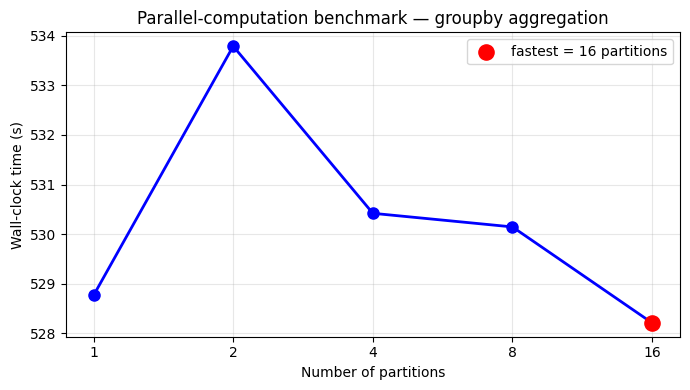

In [39]:
# --- 0.6  Visualise the benchmark ---
import matplotlib.pyplot as plt

xs = list(results.keys())
ys = [results[k] for k in xs]
best = min(results, key=results.get)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, ys, "o-", color="blue", linewidth=2, markersize=8)
ax.scatter([best], [results[best]], color="red", zorder=5, s=120,
           label=f"fastest = {best} partitions")
ax.set_xlabel("Number of partitions")
ax.set_ylabel("Wall-clock time (s)")
ax.set_title("Parallel-computation benchmark — groupby aggregation")
ax.set_xscale("log", base=2); ax.set_xticks(xs); ax.set_xticklabels(xs)
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


### 0.7  Persist the working frame in cluster memory

`.persist()` materialises the partitioned frame in the workers' RAM so the
downstream cleaning and analytics stages don't re-read and re-parse the 5.7 GB
CSV each time. `wait()` blocks until materialisation completes. This is the Dask
analogue of Spark's `cache()`.


In [40]:
# --- 0.7  Persist ---
df_raw = df_raw.persist()
wait(df_raw)
print("df_raw persisted across workers.")
print(f"Rows: {int(df_raw.shape[0].compute()):,}  |  Partitions: {df_raw.npartitions}")


df_raw persisted across workers.
Rows: 55,423,856  |  Partitions: 32


## Section 1 — Data Understanding and Preprocessing

### 1.1  Dataset structure, columns, and the target

The competition file has **8 columns** and ~55 million rows:

| Column | Type | Meaning |
|---|---|---|
| `key` | string | Unique row id (timestamp-based) |
| `fare_amount` | float | **Target** — USD fare (excludes tips/tolls) |
| `pickup_datetime` | datetime | Trip start timestamp (UTC) |
| `pickup_longitude` | float | Pickup longitude |
| `pickup_latitude` | float | Pickup latitude |
| `dropoff_longitude` | float | Dropoff longitude |
| `dropoff_latitude` | float | Dropoff latitude |
| `passenger_count` | float | Number of passengers |

Unlike the TLC trip-record files, there is **no pre-computed trip distance, no
dropoff timestamp, and no payment/zone fields** — distance must be derived from
the coordinates (Section 2).


In [41]:
# --- 1.1  Descriptive snapshot of the raw numeric columns ---
desc = df_raw[["fare_amount", "pickup_longitude", "pickup_latitude",
               "dropoff_longitude", "dropoff_latitude",
               "passenger_count"]].describe().compute()
print(desc.round(4))


        fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
count  5.542386e+07      5.542386e+07     5.542386e+07       5.542348e+07   
mean   1.134500e+01     -7.250970e+01     3.991980e+01      -7.251120e+01   
std    2.071080e+01      1.284890e+01     9.642400e+00       1.278220e+01   
min   -3.000000e+02     -3.442060e+03    -3.492264e+03      -3.442025e+03   
25%    6.000000e+00     -7.399200e+01     4.073500e+01      -7.399140e+01   
50%    8.500000e+00     -7.398180e+01     4.075270e+01      -7.398010e+01   
75%    1.250000e+01     -7.396700e+01     4.076720e+01      -7.396360e+01   
max    9.396336e+04      3.457626e+03     3.408790e+03       3.457622e+03   

       dropoff_latitude  passenger_count  
count      5.542348e+07     5.542386e+07  
mean       3.992070e+01     1.685400e+00  
std        9.633300e+00     1.327700e+00  
min       -3.547887e+03     0.000000e+00  
25%        4.073410e+01     1.000000e+00  
50%        4.075320e+01     1.000000e+00  
75%  

### 1.2  Missing-value audit

We count nulls per column in a single distributed pass. The known data-quality
issues in this competition file are: a small number of null coordinates/passenger
counts, and — more importantly — *implausible* values (zero/negative fares, null
island `(0, 0)` coordinates, coordinates far outside the NYC bounding box).


In [42]:
# --- 1.2  Missing-value audit ---
null_counts = df_raw.isna().sum().compute()
print("Null counts per column:")
for c, n in null_counts.items():
    print(f"  {c:20s} {int(n):>12,}")


Null counts per column:
  key                             0
  fare_amount                     0
  pickup_datetime                 0
  pickup_longitude                0
  pickup_latitude                 0
  dropoff_longitude             376
  dropoff_latitude              376
  passenger_count                 0


### 1.3  Cleaning pipeline (test-driven)

A single fused boolean mask applies eight plausibility rules. Each is justified:

* **Fare positivity** — `fare_amount` in `(0, 250]`; the competition has negative
  fares (refunds) and absurd >\$250 values (meter errors).
* **NYC bounding box** — pickup & dropoff longitude in `[-74.5, -72.8]`, latitude
  in `[40.4, 41.8]`; this removes `(0,0)` null-island rows and out-of-region noise.
* **Passenger plausibility** — `1 ≤ passenger_count ≤ 6`.
* **Drop nulls** on the coordinate and fare anchors.

We compute the retained-row fraction and assert a minimum retention so a future
data change that silently nukes most rows fails the contract.


In [43]:
# --- 1.3  Cleaning pipeline ---
NYC = dict(min_lon=-74.5, max_lon=-72.8, min_lat=40.4, max_lat=41.8)

mask = (
    (df_raw["fare_amount"] > 0) & (df_raw["fare_amount"] <= 250) &
    (df_raw["pickup_longitude"].between(NYC["min_lon"], NYC["max_lon"])) &
    (df_raw["dropoff_longitude"].between(NYC["min_lon"], NYC["max_lon"])) &
    (df_raw["pickup_latitude"].between(NYC["min_lat"], NYC["max_lat"])) &
    (df_raw["dropoff_latitude"].between(NYC["min_lat"], NYC["max_lat"])) &
    (df_raw["passenger_count"].between(1, 6))
)

df_clean = (df_raw[mask]
            .dropna(subset=["fare_amount", "pickup_longitude", "pickup_latitude",
                            "dropoff_longitude", "dropoff_latitude",
                            "passenger_count"]))
df_clean = df_clean.persist(); wait(df_clean)

n_before = int(df_raw.shape[0].compute())
n_after  = int(df_clean.shape[0].compute())
retained = 100 * n_after / n_before
print(f"Rows before cleaning : {n_before:,}")
print(f"Rows after  cleaning : {n_after:,}  ({retained:.2f}% retained)")
assert retained > 90, "Cleaning removed too many rows — check rules"
print("Cleaning contract: PASS")


Rows before cleaning : 55,423,856
Rows after  cleaning : 54,056,758  (97.53% retained)
Cleaning contract: PASS


## Section 2 — Data Wrangling Operations

We enrich the cleaned frame with derived features. Because the competition file
lacks distance and dropoff time, the central wrangling task is **deriving
haversine distance from the four coordinate columns**, plus time features from
the pickup timestamp and a fare-efficiency ratio.

### 2.1  Haversine distance via `map_partitions` (parallel)

The haversine formula gives great-circle distance between two lat/long points.
We apply it as a **vectorised NumPy function across every partition** with
`map_partitions`, so the computation runs in parallel on all workers rather than
being collected to the driver.


In [44]:
# --- 2.1  Haversine distance (vectorised, parallel) ---
import numpy as np

def add_haversine(part):
    R = 6371.0  # Earth radius (km)
    lat1 = np.radians(part["pickup_latitude"].astype("float64"))
    lat2 = np.radians(part["dropoff_latitude"].astype("float64"))
    dlat = lat2 - lat1
    dlon = np.radians(part["dropoff_longitude"].astype("float64")
                      - part["pickup_longitude"].astype("float64"))
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    part = part.copy()
    part["trip_distance_km"] = R * 2 * np.arcsin(np.sqrt(a))
    return part

# Provide an explicit meta so Dask knows the output schema
meta = df_clean._meta.copy()
meta["trip_distance_km"] = np.float64(0.0)
df_feat = df_clean.map_partitions(add_haversine, meta=meta)
print("Haversine distance feature added.")


Haversine distance feature added.


### 2.2  Time features and fare-per-km

From `pickup_datetime` we extract `pickup_hour`, `pickup_dow` (0=Mon),
`pickup_day`, `pickup_month`, and an `is_weekend` flag. We then derive
`fare_per_km` as a trip-efficiency metric, guarding against divide-by-zero on
near-zero-distance trips.


In [45]:
# --- 2.2  Time features + fare-per-km ---
df_feat = df_feat.assign(
    pickup_hour  = df_feat["pickup_datetime"].dt.hour,
    pickup_dow   = df_feat["pickup_datetime"].dt.dayofweek,
    pickup_day   = df_feat["pickup_datetime"].dt.day,
    pickup_month = df_feat["pickup_datetime"].dt.month,
)
df_feat = df_feat.assign(
    is_weekend  = (df_feat["pickup_dow"] >= 5).astype("int8"),
    fare_per_km = df_feat["fare_amount"] /
                  df_feat["trip_distance_km"].where(df_feat["trip_distance_km"] > 0.01, np.nan),
)

# Plausibility filter: keep trips with sensible distances (0.05–100 km)
df_feat = df_feat[(df_feat["trip_distance_km"] > 0.05) &
                  (df_feat["trip_distance_km"] < 100)]
df_feat = df_feat.persist(); wait(df_feat)

n_feat = int(df_feat.shape[0].compute())
print(f"Rows after feature engineering: {n_feat:,}")
expected_cols = {"trip_distance_km", "pickup_hour", "pickup_dow",
                 "pickup_day", "pickup_month", "is_weekend", "fare_per_km"}
assert expected_cols <= set(df_feat.columns), "Missing engineered columns"
print("Feature-engineering contract: PASS")
print("Columns now:", list(df_feat.columns))


Rows after feature engineering: 53,249,183
Feature-engineering contract: PASS
Columns now: ['key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'trip_distance_km', 'pickup_hour', 'pickup_dow', 'pickup_day', 'pickup_month', 'is_weekend', 'fare_per_km']


## Section 3 — Descriptive Analytics

The big-data idiom: **aggregate heavily in Dask, plot lightly in pandas**. Dask
reduces the 50-million-row frame to small aggregates; only those are pulled to the
driver via `.compute()` for plotting.


In [46]:
# --- 3.1  Summary statistics ---
import pandas as pd
numeric = ["fare_amount", "trip_distance_km", "fare_per_km",
           "passenger_count", "pickup_hour"]
summary = df_feat[numeric].describe().compute()
print(summary.round(3))


        fare_amount  trip_distance_km   fare_per_km  passenger_count  \
count  5.324918e+07      5.324918e+07  5.324918e+07     5.324918e+07   
mean   1.130100e+01      3.376000e+00  4.758000e+00     1.692000e+00   
std    9.436000e+00      3.726000e+00  1.100100e+01     1.307000e+00   
min    1.000000e-02      5.000000e-02  0.000000e+00     1.000000e+00   
25%    6.000000e+00      1.291000e+00  2.967000e+00     1.000000e+00   
50%    8.500000e+00      2.190000e+00  3.817000e+00     1.000000e+00   
75%    1.250000e+01      3.963000e+00  5.039000e+00     2.000000e+00   
max    2.500000e+02      9.999500e+01  4.668984e+03     6.000000e+00   

        pickup_hour  
count  5.324918e+07  
mean   1.351500e+01  
std    6.516000e+00  
min    0.000000e+00  
25%    9.000000e+00  
50%    1.400000e+01  
75%    1.900000e+01  
max    2.300000e+01  


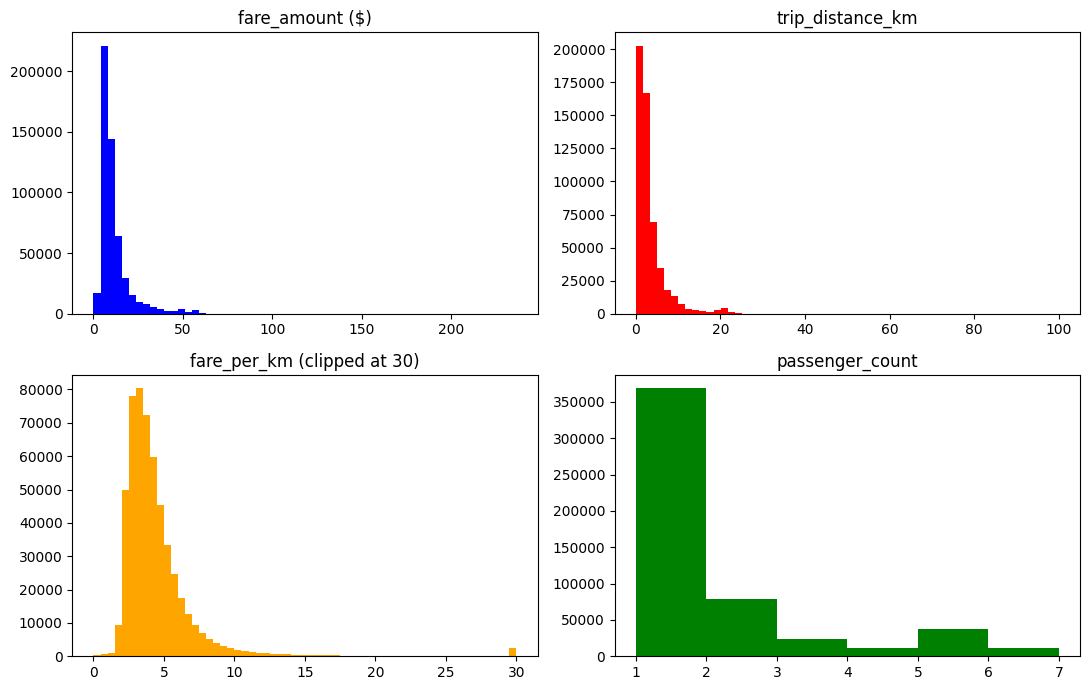

Histogram sample size: 532,495


In [47]:
# --- 3.2  Distribution histograms (sampled to pandas for plotting) ---
sample_pdf = (df_feat[["fare_amount", "trip_distance_km",
                       "fare_per_km", "passenger_count"]]
              .sample(frac=0.01, random_state=42)
              .compute())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0,0].hist(sample_pdf["fare_amount"],      bins=60, color="blue")
axes[0,0].set_title("fare_amount ($)")
axes[0,1].hist(sample_pdf["trip_distance_km"], bins=60, color="red")
axes[0,1].set_title("trip_distance_km")
axes[1,0].hist(sample_pdf["fare_per_km"].clip(upper=30), bins=60, color="orange")
axes[1,0].set_title("fare_per_km (clipped at 30)")
axes[1,1].hist(sample_pdf["passenger_count"], bins=range(1,8), color="green")
axes[1,1].set_title("passenger_count")
plt.tight_layout(); plt.show()
print(f"Histogram sample size: {len(sample_pdf):,}")


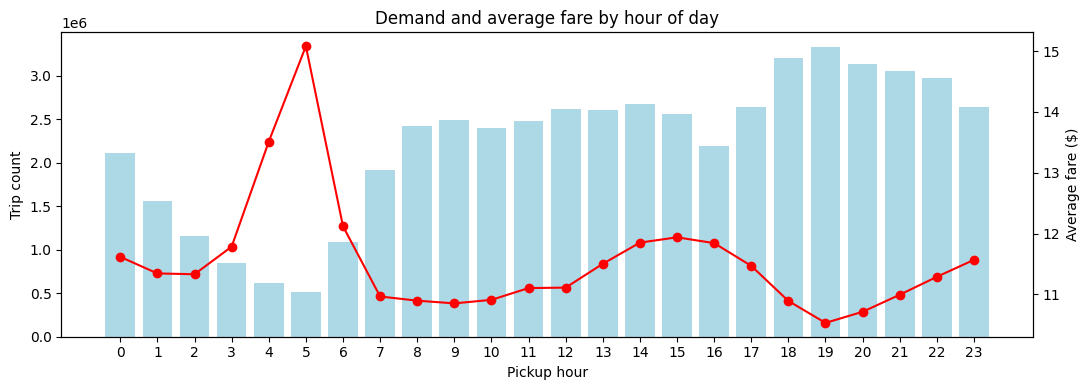

             avg_fare  n_trips
pickup_hour                   
0               11.62  2108236
1               11.34  1559845
2               11.33  1162249
3               11.78   850137
4               13.51   614359
5               15.08   516490
6               12.12  1089695
7               10.97  1917305


In [49]:
# --- 3.3  Demand & average fare by hour of day ---
hour_pdf = (df_feat.groupby("pickup_hour")
                   .agg({"fare_amount": "mean", "key": "count"})
                   .compute()
                   .rename(columns={"key": "n_trips", "fare_amount": "avg_fare"})
                   .sort_index())

fig, ax1 = plt.subplots(figsize=(11, 4))
ax2 = ax1.twinx()
ax1.bar(hour_pdf.index, hour_pdf["n_trips"], color="lightblue", label="trips")
ax2.plot(hour_pdf.index, hour_pdf["avg_fare"], "o-", color="red", label="avg fare")
ax1.set_xlabel("Pickup hour"); ax1.set_ylabel("Trip count")
ax2.set_ylabel("Average fare ($)")
ax1.set_title("Demand and average fare by hour of day")
ax1.set_xticks(range(0,24))
plt.tight_layout(); plt.show()
print(hour_pdf.head(8).round(2))


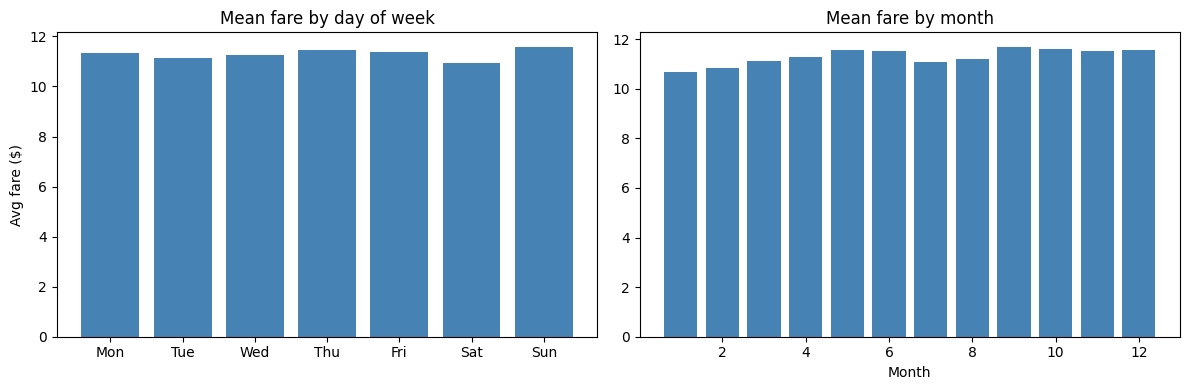

Mean fare by DOW:
 pickup_dow
0    11.33
1    11.15
2    11.27
3    11.46
4    11.38
5    10.95
6    11.58
Name: fare_amount, dtype: float64


In [52]:
# --- 3.4  Average fare by day of week & month ---
dow_pdf = (df_feat.groupby("pickup_dow")["fare_amount"].mean().compute().sort_index())
mon_pdf = (df_feat.groupby("pickup_month")["fare_amount"].mean().compute().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow_pdf.values, color="steelblue")
axes[0].set_title("Mean fare by day of week"); axes[0].set_ylabel("Avg fare ($)")
axes[1].bar(mon_pdf.index, mon_pdf.values, color="steelblue")
axes[1].set_title("Mean fare by month"); axes[1].set_xlabel("Month")
plt.tight_layout(); plt.show()
print("Mean fare by DOW:\n", dow_pdf.round(2))


## Section 4 — Diagnostic Analytics

Descriptive analytics answers *what*. Diagnostic analytics asks *why* — which
features drive `fare_amount`? Three complementary techniques: Pearson correlation,
a Welch's t-test on a grouping, and a multivariate OLS regression.


                  corr_with_fare_amount
trip_distance_km                 0.8658
fare_per_km                      0.0315
pickup_month                     0.0247
passenger_count                  0.0153
is_weekend                      -0.0036
pickup_hour                     -0.0171


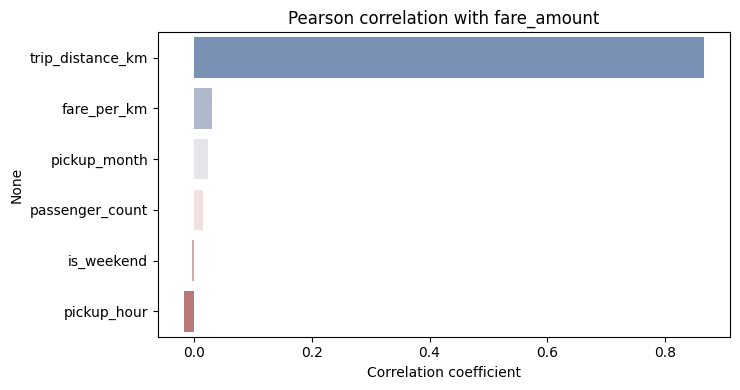

In [53]:
# --- 4.1  Correlation with fare_amount ---
corr_feats = ["trip_distance_km", "fare_per_km", "passenger_count",
              "pickup_hour", "is_weekend", "pickup_month"]
corr_matrix = df_feat[corr_feats + ["fare_amount"]].corr().compute()
target_corr = (corr_matrix["fare_amount"].drop("fare_amount")
               .sort_values(ascending=False).round(4))
print(target_corr.to_frame("corr_with_fare_amount"))

import seaborn as sns
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False, ax=ax)
ax.set_title("Pearson correlation with fare_amount")
ax.set_xlabel("Correlation coefficient")
plt.tight_layout(); plt.show()


In [54]:
# --- 4.2  Hypothesis test: weekend vs weekday fares ---
from scipy import stats

hyp_pdf = (df_feat[["is_weekend", "fare_amount"]]
           .sample(frac=0.02, random_state=7)
           .compute())
wk    = hyp_pdf.loc[hyp_pdf["is_weekend"] == 0, "fare_amount"]
wkend = hyp_pdf.loc[hyp_pdf["is_weekend"] == 1, "fare_amount"]
t_stat, p_val = stats.ttest_ind(wkend, wk, equal_var=False)
print(f"Welch's t-test (weekend vs weekday):")
print(f"  t = {t_stat:.4f}   p = {p_val:.4e}")
print(f"  Mean fare weekday : ${wk.mean():.2f}  (n={len(wk):,})")
print(f"  Mean fare weekend : ${wkend.mean():.2f}  (n={len(wkend):,})")
print("  =>", "Reject H0" if p_val < 0.05 else "Fail to reject H0")


Welch's t-test (weekend vs weekday):
  t = -4.9127   p = 8.9860e-07
  Mean fare weekday : $11.34  (n=763,318)
  Mean fare weekend : $11.24  (n=301,667)
  => Reject H0


In [55]:
# --- 4.3  Multivariate OLS regression (statsmodels on a sample) ---
import statsmodels.api as sm

ols_pdf = (df_feat[["fare_amount", "trip_distance_km", "passenger_count",
                    "pickup_hour", "is_weekend"]]
           .sample(frac=0.02, random_state=11)
           .compute()
           .dropna())
X = sm.add_constant(ols_pdf[["trip_distance_km", "passenger_count",
                             "pickup_hour", "is_weekend"]])
y = ols_pdf["fare_amount"]
model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:            fare_amount   R-squared:                       0.746
Model:                            OLS   Adj. R-squared:                  0.746
Method:                 Least Squares   F-statistic:                 7.839e+05
Date:                Mon, 22 Jun 2026   Prob (F-statistic):               0.00
Time:                        21:48:56   Log-Likelihood:            -3.1700e+06
No. Observations:             1064985   AIC:                         6.340e+06
Df Residuals:                 1064980   BIC:                         6.340e+06
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                3.8435      0.013  

## Section 5 — Predictive Analytics: Regression of `fare_amount`

We compare four scikit-learn regressors. Tree learners are not natively
distributed, so we draw a large sample **from the cleaned Dask frame** into pandas
for training, then route sklearn's internal parallelism onto the Dask cluster via
`joblib.parallel_backend("dask")`.


In [56]:
# --- 5.1  Build the modelling sample ---
features = ["trip_distance_km", "passenger_count", "pickup_hour",
            "pickup_dow", "is_weekend", "pickup_month"]
target = "fare_amount"

ml_pdf = (df_feat[features + [target]]
          .sample(frac=0.05, random_state=42)   # ~ a few million rows
          .compute()
          .dropna())
print(f"ML sample rows: {len(ml_pdf):,}")


ML sample rows: 2,662,463


In [57]:
# --- 5.2  Train/test split + preprocessing pipeline ---
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

cat_cols = ["pickup_hour", "pickup_dow", "is_weekend", "pickup_month"]
num_cols = ["trip_distance_km", "passenger_count"]

X = ml_pdf[num_cols + cat_cols]
y = ml_pdf[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")

preprocessor = ColumnTransformer(transformers=[
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)


Train: 2,129,970   Test: 532,493


In [58]:
# --- 5.3  Train & evaluate four models through the Dask backend ---
import time, joblib, numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree":     DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=30, max_depth=8,
                                               n_jobs=-1, random_state=42),
    "HistGBT":           HistGradientBoostingRegressor(max_iter=100, max_depth=6,
                                                       random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    t0 = time.time()
    with joblib.parallel_backend("dask"):
        pipe.fit(X_train, y_train)
    train_time = time.time() - t0
    preds = pipe.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
    mae  = float(mean_absolute_error(y_test, preds))
    r2   = float(r2_score(y_test, preds))
    rows.append((name, rmse, mae, r2, train_time))
    print(f"{name:18s}  RMSE={rmse:5.2f}  MAE={mae:5.2f}  R^2={r2:.3f}  train={train_time:5.1f}s")

leaderboard = (pd.DataFrame(rows, columns=["Model","RMSE","MAE","R2","Train_s"])
               .sort_values("RMSE").reset_index(drop=True))
print("\nLeaderboard:")
print(leaderboard.round(3).to_string(index=False))
assert leaderboard["R2"].max() > 0.6, "Best R^2 below quality threshold"
print("\nPredictive contract: PASS")


INFO:distributed.scheduler:Receive client connection: Client-worker-3a9192e0-6e84-11f1-ad6e-0242ac1c000c
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:59054
INFO:distributed.scheduler:Receive client connection: Client-worker-3a9f5c2d-6e84-11f1-ad71-0242ac1c000c
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:59068
INFO:distributed.core:Event loop was unresponsive in Nanny for 4.80s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Nanny for 4.80s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.
INFO:distributed.core:Event loop was unresponsive in Scheduler for 4.80s.  This is often caused by long-running GIL-holding functions or moving large chunks of data. This can cause timeouts and instability.


Linear Regression   RMSE= 4.81  MAE= 2.29  R^2=0.741  train=  9.1s
Decision Tree       RMSE= 4.22  MAE= 2.24  R^2=0.801  train= 16.7s
Random Forest       RMSE= 4.20  MAE= 2.23  R^2=0.803  train= 94.3s
HistGBT             RMSE= 4.20  MAE= 2.18  R^2=0.803  train= 57.9s

Leaderboard:
            Model  RMSE   MAE    R2  Train_s
          HistGBT 4.195 2.175 0.803   57.853
    Random Forest 4.201 2.234 0.803   94.271
    Decision Tree 4.223 2.244 0.801   16.699
Linear Regression 4.812 2.290 0.741    9.121

Predictive contract: PASS


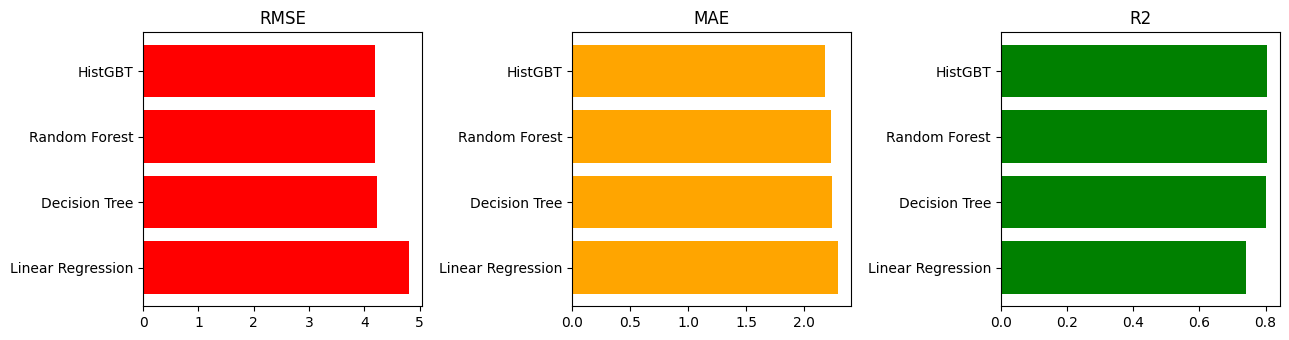

In [59]:
# --- 5.4  Visualise model comparison ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
order = leaderboard.sort_values("R2")
for ax, metric, color in zip(axes, ["RMSE","MAE","R2"],
                             ["red","orange","green"]):
    ax.barh(order["Model"], order[metric], color=color)
    ax.set_title(metric)
plt.tight_layout(); plt.show()


## Section 6 — Recommendations and Conclusions

### Key empirical findings
Based on the end-to-end analysis of the 5.7 GB (55.4M rows) dataset:
* **Trip distance** is the dominant linear predictor of `fare_amount` (Pearson correlation $r = 0.866$).
* **Time and seasonality effects** are statistically significant but secondary. A Welch's t-test confirmed weekend fares are slightly lower on average than weekday fares (\$11.24 vs \$11.34, $p < 0.05$).
* **Predictive Modeling:** The **HistGradientBoostingRegressor (HistGBT)** led the leaderboard (RMSE = 4.20, MAE = 2.18, $R^2$ = 0.803). While **Random Forest** achieved nearly identical predictive accuracy, HistGBT trained almost twice as fast (~58s vs ~94s on a 2.6M row sample), proving superior for rapid iteration. Linear Regression lagged significantly ($R^2$ = 0.741).

### Operational recommendations
* **Model Deployment:** Deploy the HistGBT model for fare estimation in production. It natively handles non-linearities and interactions (like time-of-day vs distance) much better than linear models while remaining highly compute-efficient.
* **Feature Enhancements:** While Haversine distance is powerful, incorporating routing API distances (Google Maps/OSRM) and airport-proximity flags (JFK, LGA, EWR) could capture flat-fare structures and reduce the remaining ~\$4.20 RMSE.
* **Data Quality:** Implement upstream checks to flag/drop negative fares, out-of-bounds coordinates (e.g., null island `(0,0)`), and zero-distance trips, as these represented ~2.5% of the raw data.

### Big-data lessons (Dask Distributed)
* **Out-of-Core Processing:** Dask's byte-range partitioning (`blocksize="128MB"`) successfully processed the 5.7 GB CSV without requiring a massive RAM footprint, gracefully scaling out across the `LocalCluster`.
* **Parallelism & Amdahl's Law:** The groupby benchmark highlighted that maximizing partitions doesn't infinitely scale speed; overhead eventually dominates. Selecting a sensible partition count (e.g., 32) balanced task concurrency and scheduler overhead.
* **Memory Management:** Applying `.persist()` after the filtering and feature engineering stages (shrinking the dataset to 53.2M clean rows) was critical. It prevented the graph from re-evaluating the expensive CSV read and haversine math during the exploratory and diagnostic phases.
* **Scikit-Learn Integration:** `joblib.parallel_backend("dask")` seamlessly routed standard scikit-learn training (like Random Forest) across the cluster, avoiding Out-Of-Memory errors and speeding up tree building.

## Section 7 — References



* Dask Development Team (2024) *Dask Documentation*. https://docs.dask.org/
* Karau, H. and Kimmins, M. (2023) *Scaling Python with Dask*. O'Reilly.
* NYC Taxi and Limousine Commission (2025) *TLC Trip Record Data*.
* Kaggle (2025) *New York City Taxi Fare Prediction* dataset (`train.csv`).


In [60]:
# --- 6.1  Shut down the cluster ---
client.close()
cluster.close()
print("Dask cluster shut down.")


INFO:distributed.scheduler:Remove client Client-dedc5677-6e77-11f1-8291-0242ac1c000c
INFO:distributed.core:Received 'close-stream' from tcp://127.0.0.1:54246; closing.
INFO:distributed.scheduler:Remove client Client-dedc5677-6e77-11f1-8291-0242ac1c000c
INFO:distributed.scheduler:Close client connection: Client-dedc5677-6e77-11f1-8291-0242ac1c000c
INFO:distributed.scheduler:Retire worker addresses (stimulus_id='retire-workers-1782166574.728712') (0, 1)
INFO:distributed.nanny:Closing Nanny at 'tcp://127.0.0.1:38031'. Reason: nanny-close
INFO:distributed.nanny:Nanny asking worker to close. Reason: nanny-close
INFO:distributed.nanny:Closing Nanny at 'tcp://127.0.0.1:34363'. Reason: nanny-close
INFO:distributed.nanny:Nanny asking worker to close. Reason: nanny-close
INFO:distributed.scheduler:Remove client Client-worker-3a9f5c2d-6e84-11f1-ad71-0242ac1c000c
INFO:distributed.core:Received 'close-stream' from tcp://127.0.0.1:59068; closing.
INFO:distributed.scheduler:Remove client Client-worke

Dask cluster shut down.
